# PageRank as Graph Theory: A Hands-On Companion

**Paper:** Page, Brin, Motwani, and Winograd, *The PageRank Citation Ranking: Bringing Order to the Web* (Stanford draft dated January 29, 1998; published as Stanford InfoLab Technical Report 1999-66).

This notebook rebuilds each idea in the paper from scratch so you can poke at it. Every section maps to a section of the paper:

| Notebook section | Paper section | Graph theory idea |
|---|---|---|
| 1. Pages as a directed graph | 2.2 | Directed graphs, in-degree, out-degree |
| 2. Why counting backlinks fails | 2.1 to 2.3 | Degree centrality vs. recursive centrality |
| 3. The simplified ranking | 2.3 to 2.4, Figs. 2 and 3 | Flow conservation on a graph |
| 4. The matrix view | 2.4 | Adjacency and transition matrices, eigenvectors |
| 5. Rank sinks | 2.4, Fig. 4 | Closed (absorbing) strongly connected components |
| 6. Dangling links | 2.7, 3.1 | Sinks, sub-stochastic matrices |
| 7. Rank source E and the random surfer | 2.4 to 2.6 | Markov chains, stationary distributions |
| 8. Convergence and expander graphs | 4, Fig. 5 | Spectral gap, rapid mixing, expansion |
| 9. Personalized PageRank | 6, Table 2 | Random walk with restart |
| 10. Manipulation and link farms | 6.1 | Reachability from the restart set |
| 11. PageRank vs. HITS | 2.1 (Kleinberg) | Alternative eigenvector centralities |

**How to use it:** run top to bottom once, then go back and change the graphs. The "Try it" prompts suggest edits that break or bend each idea.

**Running analogy for the whole notebook:** think of PageRank as *water flowing through a network of pipes*. Every page holds some water (its rank). Each round, every page pours its water out evenly through its outgoing pipes. Most of the paper's problems are plumbing problems: basins with no drain (rank sinks), pipes that lead nowhere (dangling links), and the fix is a sprinkler system (the E vector) that rains fresh water on everyone.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import scipy.sparse as sp

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)
plt.rcParams["figure.dpi"] = 100

def draw(G, ranks=None, title="", pos=None, ax=None, edge_labels=None, seed=3):
    # Draw a directed graph; node size and label reflect rank if given.
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    if pos is None:
        pos = nx.spring_layout(G, seed=seed)
    if ranks is None:
        sizes = 900
        labels = {n: str(n) for n in G}
    else:
        r = np.array([ranks[n] for n in G])
        sizes = 400 + 3000 * r / r.max()
        labels = {n: f"{n}\n{ranks[n]:.3f}" for n in G}
    nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color="#cfe3ff", edgecolors="#1f4e8c", ax=ax)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, ax=ax)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=16, edge_color="#c0392b",
                           connectionstyle="arc3,rad=0.12", node_size=sizes, ax=ax)
    if edge_labels:
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8,
                                     connectionstyle="arc3,rad=0.12", ax=ax)
    ax.set_title(title)
    ax.axis("off")
    return pos

## 1. Pages as a directed graph (paper Section 2.2)

The paper models the Web as a **directed graph** $G = (V, E)$: pages are nodes, hyperlinks are directed edges $u \to v$. The paper's notation:

* $F_u$: the set of pages $u$ points to (**forward links**, out-edges)
* $B_u$: the set of pages that point to $u$ (**backlinks**, in-edges)
* $N_u = |F_u|$: the **out-degree** of $u$

**Analogy:** a backlink works like a citation to your paper; a forward link works like an entry in your own bibliography. The paper explicitly borrows this framing from bibliometrics (Garfield's citation analysis, cited as [Gar95]).

**A key asymmetry the paper notes:** once a crawler downloads page $u$, it knows $F_u$ exactly, but it can never be sure it has found all of $B_u$. You can read your own bibliography, but you can't know everyone who cited you without reading everything.

Below we rebuild Figure 1 (A and B are backlinks of C).

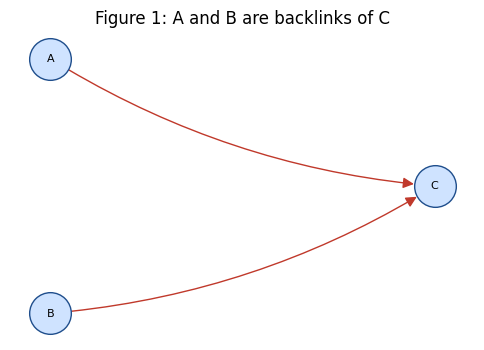

A: F_u = ['C'], B_u = [], N_u = 1
C: F_u = [], B_u = ['A', 'B'], N_u = 0
B: F_u = ['C'], B_u = [], N_u = 1


In [2]:
G1 = nx.DiGraph([("A", "C"), ("B", "C")])
draw(G1, title="Figure 1: A and B are backlinks of C",
     pos={"A": (0, 1), "B": (0, -1), "C": (1, 0)})
plt.show()

for u in G1:
    F_u = list(G1.successors(u))
    B_u = list(G1.predecessors(u))
    print(f"{u}: F_u = {F_u}, B_u = {B_u}, N_u = {len(F_u)}")

## 2. Why simply counting backlinks fails (Sections 2.1 to 2.3)

The obvious first move treats in-degree (backlink count) as importance. The paper rejects this with the Yahoo example: *one* link from the Yahoo home page should count for more than many links from obscure places.

**Analogy:** compare a recommendation letter from a Nobel laureate to fifty letters from people nobody has heard of. Counting letters says the fifty win. Common sense disagrees, because the value of a recommendation depends on the recommender's own standing.

That gives the paper's recursive intuition (Section 2.3): *a page has high rank if the sum of the ranks of its backlinks is high.* Network scientists call this an **eigenvector centrality** idea, and it predates the paper (see the references on Katz 1953, Pinski and Narin 1976, and Bonacich 1987 at the end).

Let's build a toy web that pits the two ideas against each other:
* **Yahoo**: a hub that many pages link to.
* **Lucky**: gets exactly *one* backlink, from Yahoo.
* **Spammy**: gets *five* backlinks, all from throwaway pages that nobody links to.

We preview the answer with `networkx.pagerank`; Sections 3 to 7 rebuild it ourselves.

In [3]:
G2 = nx.DiGraph()
fans = [f"fan{i}" for i in range(20)]           # 20 ordinary pages that link to Yahoo
G2.add_edges_from((f, "Yahoo") for f in fans)
G2.add_edges_from([("Yahoo", "Lucky"), ("Yahoo", "Other")])
G2.add_edges_from([("Lucky", "Yahoo"), ("Other", "Yahoo")])
junk = [f"junk{i}" for i in range(5)]           # 5 throwaway pages created to boost Spammy
G2.add_edges_from((j, "Spammy") for j in junk)
G2.add_edge("Spammy", "Yahoo")
G2.add_edges_from((f, "fan" + str((int(f[3:]) + 1) % 20)) for f in fans)  # fans link to each other

pr = nx.pagerank(G2, alpha=0.85)
df = pd.DataFrame({
    "backlinks (in-degree)": dict(G2.in_degree()),
    "PageRank": pr,
}).loc[["Yahoo", "Lucky", "Spammy", "Other", "fan0", "junk0"]]
df["rank by backlinks"] = df["backlinks (in-degree)"].rank(ascending=False, method="min").astype(int)
df["rank by PageRank"] = df["PageRank"].rank(ascending=False, method="min").astype(int)
df.round(4)

,backlinks (in-degree),PageRank,rank by backlinks,rank by PageRank
Yahoo,23,0.4090,1,1
Lucky,1,0.1790,3,2
Spammy,5,0.0272,2,4
Other,1,0.1790,3,2
fan0,1,0.0090,3,5
junk0,0,0.0052,6,6


**What to notice:** Spammy beats Lucky on backlink count (5 vs. 1) but loses on PageRank, because Lucky's single backlink comes from a page that itself carries a lot of rank. This is the paper's Yahoo argument in executable form.

> **Try it:** raise the number of junk pages from 5 to 50. At what point does Spammy pass Lucky? Section 10 returns to this "link farm" attack and shows how the E vector changes the answer.

## 3. The simplified ranking as flow (Sections 2.3 to 2.4, Figures 2 and 3)

The paper's first formula:

$$R(u) = c \sum_{v \in B_u} \frac{R(v)}{N_v}$$

Read it as a **flow rule**: each page $v$ splits its current rank *evenly* across its $N_v$ out-links, and each page $u$ collects whatever flows in. The constant $c$ rescales so total rank stays fixed.

**Analogy (the water pipes):** each page holds a bucket of water. Every round, it pours its bucket evenly into its outgoing pipes. Figure 2 in the paper shows exactly this: a page holding 100 with two out-links sends 50 down each pipe; a page holding 9 with three out-links sends 3 down each.

The formula is **recursive** (rank depends on rank), so the paper solves it by **iteration**: start with any guess and keep applying the flow rule until nothing changes. The settled state is a **fixed point** (the paper calls it a "steady state solution," Figure 3).

Steady state: {'A': 0.4, 'B': 0.2, 'C': 0.4}
Paper's Figure 3 shows A = 0.4, B = 0.2, C = 0.4


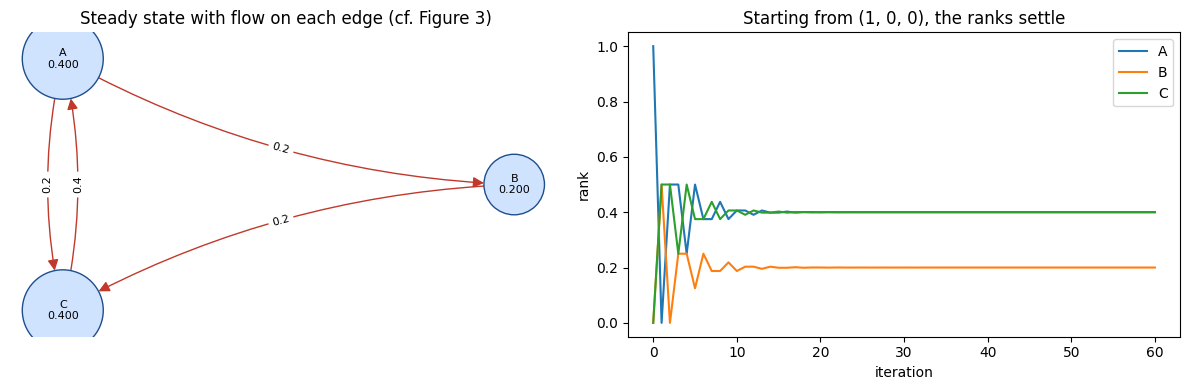

In [4]:
def simplified_step(G, R, nodes):
    # One application of R(u) = sum_{v in B_u} R(v)/N_v  (no normalization).
    idx = {n: i for i, n in enumerate(nodes)}
    new = np.zeros(len(nodes))
    for v in nodes:
        Nv = G.out_degree(v)
        if Nv == 0:
            continue                      # dangling: its rank goes nowhere (Section 6)
        for u in G.successors(v):
            new[idx[u]] += R[idx[v]] / Nv
    return new

def simplified_pagerank(G, iters=100, R0=None, normalize=True):
    nodes = list(G)
    R = np.ones(len(nodes)) / len(nodes) if R0 is None else np.array(R0, float)
    history = [R.copy()]
    for _ in range(iters):
        R = simplified_step(G, R, nodes)
        if normalize and R.sum() > 0:
            R = R / R.sum()               # this division plays the role of c
        history.append(R.copy())
    return dict(zip(nodes, R)), np.array(history), nodes

# Figure 3 of the paper: A->B, A->C, B->C, C->A
G3 = nx.DiGraph([("A", "B"), ("A", "C"), ("B", "C"), ("C", "A")])
ranks3, hist3, nodes3 = simplified_pagerank(G3, iters=60, R0=[1, 0, 0])   # deliberately bad start
print("Steady state:", {k: round(float(v), 4) for k, v in ranks3.items()})
print("Paper's Figure 3 shows A = 0.4, B = 0.2, C = 0.4")

flows = {(v, u): f"{ranks3[v] / G3.out_degree(v):.1f}" for v, u in G3.edges()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw(G3, ranks3, "Steady state with flow on each edge (cf. Figure 3)",
     pos={"A": (0, 1), "B": (1, 0.3), "C": (0, -0.4)}, ax=axes[0], edge_labels=flows)
for i, n in enumerate(nodes3):
    axes[1].plot(hist3[:, i], label=n)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("rank"); axes[1].legend()
axes[1].set_title("Starting from (1, 0, 0), the ranks settle")
plt.tight_layout(); plt.show()

**Check the fixed point by hand.** A holds 0.4 and has 2 out-links, so it sends 0.2 to B and 0.2 to C. B holds 0.2 and sends all of it to C. C collects 0.2 + 0.2 = 0.4 and sends it all to A. Every page receives exactly what it holds, so nothing changes. That is what "steady state" means.

**A subtle point the paper glosses over: periodicity.** The paper says the iteration converges from "any nondegenerate start vector." That claim needs the graph to be **aperiodic**. A pure cycle shows why:

In [5]:
cycle = nx.DiGraph([("A", "B"), ("B", "C"), ("C", "A")])
_, hist_c, nodes_c = simplified_pagerank(cycle, iters=12, R0=[1, 0, 0])
print("Pure 3-cycle starting at (1,0,0):")
print(pd.DataFrame(hist_c, columns=nodes_c).head(7))

Pure 3-cycle starting at (1,0,0):
     A    B    C
0  1.0  0.0  0.0
1  0.0  1.0  0.0
2  0.0  0.0  1.0
3  1.0  0.0  0.0
4  0.0  1.0  0.0
5  0.0  0.0  1.0
6  1.0  0.0  0.0


The water just sloshes around the ring forever. The G3 graph above converges because it contains cycles of length 2 (A→C→A) and 3 (A→B→C→A), whose greatest common divisor is 1. In Markov-chain language, a chain converges to its stationary distribution from any start when it is **irreducible and aperiodic** (standard result; see Norris 1997 in the references). Section 7's E vector guarantees both, which is one reason it matters.

## 4. The matrix view: PageRank is an eigenvector (Section 2.4)

The paper restates the flow rule with a matrix. Define $A_{u,v} = 1/N_u$ if there's an edge $u \to v$, else 0. Each row of $A$ describes how a page splits its rank across its out-links.

**Notation alert (my reading, confidence about 90%).** The flow rule sums over *incoming* edges, so with $A$ defined row-by-source as the paper does, the equation that matches the summation formula is $R = c\,A^{\mathsf T} R$. The paper writes $R = cAR$. The underlying idea doesn't change; the transpose depends on whether you index matrices by (from, to) or (to, from). Below I build $M = A^{\mathsf T}$ explicitly so the code matches the summation formula exactly.

$M$ is **column-stochastic** when every page has at least one out-link: each column sums to 1, because each page gives away 100% of its rank.

Then $R = cMR$ says that $R$ is an **eigenvector** of $M$. The paper wants the **dominant eigenvector** (largest eigenvalue). For a column-stochastic matrix that eigenvalue equals 1, which follows from the Perron–Frobenius theorem (Perron 1907; Frobenius 1912).

**Analogy:** an eigenvector is a shape that a transformation stretches but doesn't rotate. Think of $M$ as "one round of pouring water." The eigenvector is the arrangement of water levels that looks *the same* after a round of pouring. Repeated application of $M$ (**power iteration**) is exactly the loop from Section 3, just written as a matrix multiply.

In [6]:
def transition_matrix(G, nodes=None):
    # M[u, v] = 1/N_v if v -> u. Columns of non-dangling nodes sum to 1.
    nodes = list(G) if nodes is None else nodes
    idx = {n: i for i, n in enumerate(nodes)}
    M = np.zeros((len(nodes), len(nodes)))
    for v in nodes:
        Nv = G.out_degree(v)
        for u in G.successors(v):
            M[idx[u], idx[v]] = 1.0 / Nv
    return M, nodes

M3, nodes3 = transition_matrix(G3)
print("Nodes:", nodes3)
print("A (paper's definition, row = source):\n", M3.T)
print("M = A^T (column = source):\n", M3)
print("Column sums of M:", M3.sum(axis=0))

vals, vecs = np.linalg.eig(M3)
order = np.argsort(-np.abs(vals))
print("\nEigenvalues (sorted by magnitude):", vals[order])
dom = np.real(vecs[:, order[0]])
dom = dom / dom.sum()
print("Dominant eigenvector, scaled to sum to 1:", {k: round(float(x), 4) for k, x in zip(nodes3, dom)})

Nodes: ['A', 'B', 'C']
A (paper's definition, row = source):
 [[0.  0.5 0.5]
 [0.  0.  1. ]
 [1.  0.  0. ]]
M = A^T (column = source):
 [[0.  0.  1. ]
 [0.5 0.  0. ]
 [0.5 1.  0. ]]
Column sums of M: [1. 1. 1.]

Eigenvalues (sorted by magnitude): [ 1. +0.j  -0.5+0.5j -0.5-0.5j]
Dominant eigenvector, scaled to sum to 1: {'A': 0.4, 'B': 0.2, 'C': 0.4}


In [7]:
# Power iteration: apply M over and over to any start vector
R = np.array([1.0, 0.0, 0.0])
for i in range(8):
    print(f"iter {i}: {R.round(4)}")
    R = M3 @ R

iter 0: [1. 0. 0.]
iter 1: [0.  0.5 0.5]
iter 2: [0.5 0.  0.5]
iter 3: [0.5  0.25 0.25]
iter 4: [0.25 0.25 0.5 ]
iter 5: [0.5   0.125 0.375]
iter 6: [0.375 0.25  0.375]
iter 7: [0.375  0.1875 0.4375]


Same answer three ways: the flow loop (Section 3), `np.linalg.eig`, and power iteration. The paper uses power iteration because, for 24 million pages, you can't call `eig` on the matrix. One matrix-vector product per round only needs to stream through the link list, which matches what the paper describes in Section 3.1 (sorted links, linear disk access, about 6 minutes per iteration).

## 5. Rank sinks (Section 2.4, Figure 4)

The paper's first problem: "two web pages that point to each other but to no other page," with some other page pointing into them. Rank flows in but never flows out.

**Analogy:** a basin with an inflow pipe but no drain. Leave the water running long enough and the basin holds all of it.

**Graph theory name:** the pair forms a **closed strongly connected component** (in Markov-chain terms, a closed communicating class). Once a random walk enters it, it can't leave.

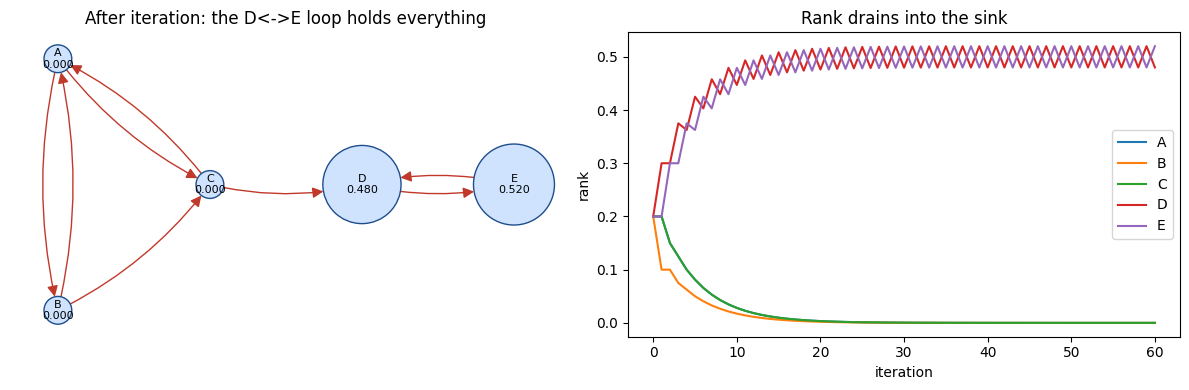

Strongly connected components: [['D', 'E'], ['A', 'B', 'C']]
Closed components (no edges leaving): [['D', 'E']]


In [8]:
Gsink = nx.DiGraph([
    ("A", "B"), ("B", "A"), ("A", "C"), ("B", "C"),
    ("C", "A"), ("C", "D"),        # C leaks some rank toward the trap
    ("D", "E"), ("E", "D"),        # D <-> E is the rank sink: no way out
])
ranks_s, hist_s, nodes_s = simplified_pagerank(Gsink, iters=60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pos_s = {"A": (0, 1), "B": (0, -1), "C": (1, 0), "D": (2, 0), "E": (3, 0)}
draw(Gsink, ranks_s, "After iteration: the D<->E loop holds everything", pos=pos_s, ax=axes[0])
for i, n in enumerate(nodes_s):
    axes[1].plot(hist_s[:, i], label=n)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("rank"); axes[1].legend()
axes[1].set_title("Rank drains into the sink")
plt.tight_layout(); plt.show()

print("Strongly connected components:", [sorted(c) for c in nx.strongly_connected_components(Gsink)])
cond = nx.condensation(Gsink)
closed = [sorted(cond.nodes[c]["members"]) for c in cond if cond.out_degree(c) == 0]
print("Closed components (no edges leaving):", closed)

A, B, and C end with essentially zero rank, even though A and B link to each other and C, so the ranking says nothing useful about them. The general rule: under the simplified ranking, **all rank ends up in the closed strongly connected components**. The real Web contains many of these traps, so the paper needs a fix (Section 7).

## 6. Dangling links (Sections 2.7 and 3.1)

The opposite plumbing problem: a page with **no out-links** (a sink node, or in the paper's terms, the target of a dangling link). Its rank has nowhere to go and disappears from the system. This is why the paper says $c < 1$ in the simplified formula: the matrix becomes **sub-stochastic** (some columns sum to 0 instead of 1), so the total keeps shrinking.

**Analogy:** a pipe that empties onto the floor. Water leaves the system every round.

In the paper's crawl, most dangling links point to pages the crawler hasn't downloaded yet (51 million undownloaded URLs vs. 24 million downloaded pages).

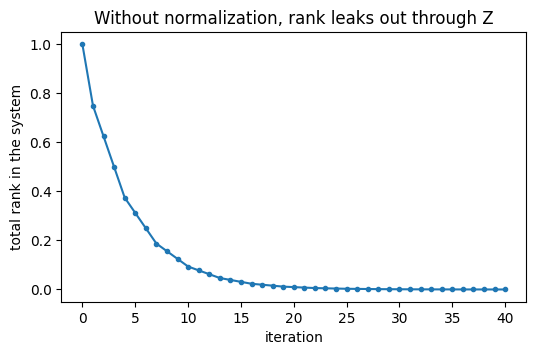

In [9]:
Gdang = nx.DiGraph([("A", "B"), ("B", "C"), ("C", "A"), ("C", "Z")])   # Z has no out-links
_, hist_d, nodes_d = simplified_pagerank(Gdang, iters=40, normalize=False)

plt.figure(figsize=(6, 3.5))
plt.plot(hist_d.sum(axis=1), marker=".")
plt.xlabel("iteration"); plt.ylabel("total rank in the system")
plt.title("Without normalization, rank leaks out through Z")
plt.show()

**The paper's fix (Section 3.1):** delete dangling nodes, compute PageRank on what remains, then add them back and run a few more iterations. Deletion can *create* new dangling nodes (a page whose only out-link pointed at a dangling page), so the paper repeats the removal: "a few iterations removes the vast majority." The code below shows that cascade.

(Modern implementations usually redistribute a dangling page's rank instead, often uniformly or according to E. `networkx.pagerank` does this, and so does the function in Section 7. See Langville and Meyer 2006, ch. 4.)

In [10]:
def strip_dangling(G, verbose=True):
    H = G.copy()
    rnd = 0
    while True:
        dangling = [n for n in H if H.out_degree(n) == 0]
        if not dangling:
            break
        rnd += 1
        if verbose:
            print(f"round {rnd}: removing {dangling}")
        H.remove_nodes_from(dangling)
    return H

chain = nx.DiGraph([("A", "B"), ("B", "A"), ("A", "X"), ("X", "Y"), ("Y", "Z")])
H = strip_dangling(chain)
print("Remaining core:", list(H.edges()))

round 1: removing ['Z']
round 2: removing ['Y']
round 3: removing ['X']
Remaining core: [('A', 'B'), ('B', 'A')]


## 7. The rank source E and the random surfer (Sections 2.4 to 2.6)

The paper fixes rank sinks by adding a **rank source** $E$:

$$R'(u) = c \sum_{v \in B_u} \frac{R'(v)}{N_v} + c\,E(u), \qquad \|R'\|_1 = 1$$

**Water analogy:** a sprinkler system rains a little fresh water on every page each round, while the pipes keep moving water around. Basins still collect water, but the sprinklers keep every other page wet.

**Random surfer analogy (the paper's own, Section 2.5):** a person clicks links at random. Now and then they get bored and jump to a random page chosen according to $E$. PageRank equals the long-run fraction of time this surfer spends on each page. Mathematically, that's the **stationary distribution** of a Markov chain.

**How E relates to the familiar "damping factor 0.85" (my derivation, confidence about 85%).** With no dangling pages, $\|MR'\|_1 = 1$, so taking the L1 norm of both sides gives $1 = c(1 + \|E\|_1)$. The paper's experiments use $\|E\|_1 = 0.15$, so $c = 1/1.15 \approx 0.870$. The surfer follows a link with probability about 0.87 and jumps with probability about 0.13. The later and now-standard way to write it (Brin and Page 1998, the "Anatomy" paper) is

$$R = \alpha M R + (1-\alpha)\, e, \qquad \alpha = 0.85,\ e \text{ a probability vector}$$

which is nearly the same model with a slightly different parameterization. Below I implement the standard form, then check it against the paper's Definition 1 solved directly as an eigenvector, and against `networkx`.

In [11]:
def pagerank(G, alpha=0.85, e=None, tol=1e-12, max_iter=1000, return_history=False):
    # Standard damped PageRank by power iteration.
    # e: dict node->weight for the jump (E) distribution; uniform if None.
    # Dangling pages send their rank according to e (same convention as networkx).
    nodes = list(G)
    n = len(nodes)
    M, _ = transition_matrix(G, nodes)
    ev = np.ones(n) / n if e is None else np.array([e.get(u, 0.0) for u in nodes], float)
    ev = ev / ev.sum()
    dangling = np.array([G.out_degree(u) == 0 for u in nodes])
    R = ev.copy()
    hist = [R.copy()]
    for _ in range(max_iter):
        R_new = alpha * (M @ R + R[dangling].sum() * ev) + (1 - alpha) * ev
        hist.append(R_new.copy())
        if np.abs(R_new - R).sum() < tol:
            R = R_new
            break
        R = R_new
    out = dict(zip(nodes, R))
    return (out, np.array(hist)) if return_history else out

def pagerank_definition1(G, E_norm=0.15):
    # Paper's Definition 1: R' is the dominant eigenvector of (M + E 1^T), uniform E.
    M, nodes = transition_matrix(G)
    n = len(nodes)
    E = np.full(n, E_norm / n)
    vals, vecs = np.linalg.eig(M + np.outer(E, np.ones(n)))
    k = np.argmax(np.real(vals))
    v = np.real(vecs[:, k]); v = v / v.sum()
    return dict(zip(nodes, v)), np.real(vals[k])

# Validate on the rank-sink graph (it has no dangling pages)
ours = pagerank(Gsink, alpha=1 / 1.15)
d1, lam = pagerank_definition1(Gsink)
nxr = nx.pagerank(Gsink, alpha=1 / 1.15, tol=1e-12, max_iter=1000)
print(f"Dominant eigenvalue of (M + E 1^T) = {lam:.4f}, so c = 1/lambda = {1/lam:.4f}")
pd.DataFrame({"standard form (alpha=1/1.15)": ours,
              "paper Definition 1": d1,
              "networkx": nxr}).round(5)

Dominant eigenvalue of (M + E 1^T) = 1.1500, so c = 1/lambda = 0.8696


,standard form (alpha=1/1.15),paper Definition 1,networkx
A,0.09950,0.09950,0.09950
B,0.06935,0.06935,0.06935
C,0.09950,0.09950,0.09950
D,0.37740,0.37740,0.37740
E,0.35426,0.35426,0.35426


All three agree, which supports the derivation above. Now look at what E does to the rank sink:

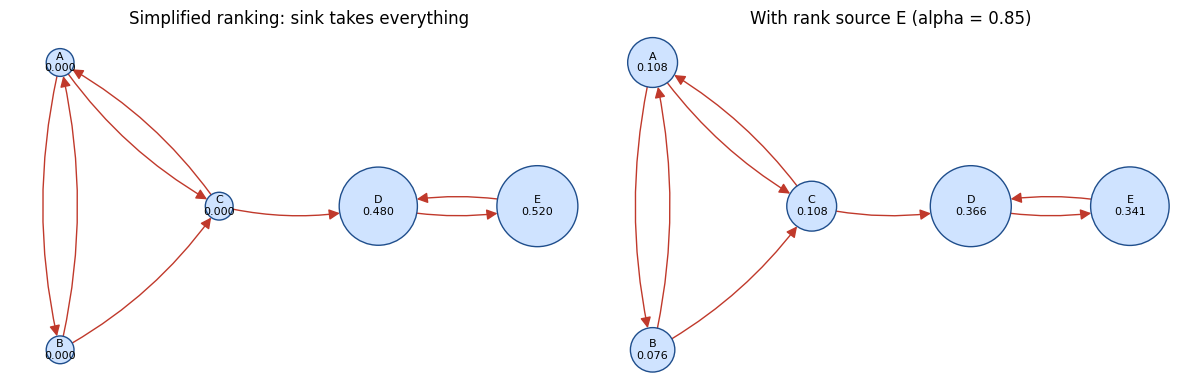

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw(Gsink, ranks_s, "Simplified ranking: sink takes everything", pos=pos_s, ax=axes[0])
draw(Gsink, pagerank(Gsink), "With rank source E (alpha = 0.85)", pos=pos_s, ax=axes[1])
plt.tight_layout(); plt.show()

The D↔E loop still ranks highest (rank flows in and only leaves through the "boredom" jumps), but A, B, and C now get meaningful, non-zero ranks.

### 7a. Simulating the random surfer

The cleanest way to *believe* the random surfer interpretation: simulate one and count visits. If the theory holds, visit frequencies should match the power-iteration answer.

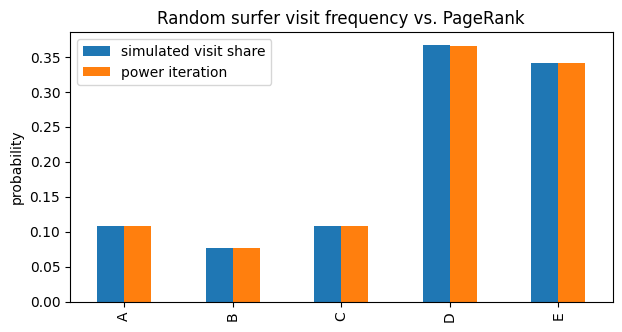

,simulated visit share,power iteration
A,0.1077,0.1084
B,0.0762,0.0761
C,0.1075,0.1084
D,0.3670,0.3660
E,0.3416,0.3411


In [13]:
def random_surfer(G, steps=200_000, alpha=0.85, seed=0):
    r = np.random.default_rng(seed)
    nodes = list(G)
    succ = {u: list(G.successors(u)) for u in nodes}
    visits = dict.fromkeys(nodes, 0)
    cur = nodes[r.integers(len(nodes))]
    for _ in range(steps):
        visits[cur] += 1
        if succ[cur] and r.random() < alpha:
            cur = succ[cur][r.integers(len(succ[cur]))]     # click a random link
        else:
            cur = nodes[r.integers(len(nodes))]             # get bored, jump (uniform E)
    return {u: c / steps for u, c in visits.items()}

sim = random_surfer(Gsink)
exact = pagerank(Gsink)
comp = pd.DataFrame({"simulated visit share": sim, "power iteration": exact})
comp.plot.bar(figsize=(7, 3.5), title="Random surfer visit frequency vs. PageRank")
plt.ylabel("probability"); plt.show()
comp.round(4)

### 7b. A wrinkle in the paper's Section 2.6 pseudocode

The paper's algorithm computes $R_{i+1} \leftarrow AR_i$, then sets $d = \|R_i\|_1 - \|R_{i+1}\|_1$ and adds $dE$. Notice what happens when no rank leaks out: $d = 0$, so **E never enters the computation**. Read literally, the pseudocode only injects E in proportion to leakage (from dangling pages), and the paper strips dangling pages before iterating (Section 3.1).

**My interpretation (confidence about 70%):** the pseudocode describes a convenient renormalization trick, and the authors' implementation likely included a decay factor not shown in the pseudocode. Definition 1 is the authoritative statement of the model. The cell below shows the literal pseudocode leaving the rank sink untouched, which is worth knowing if you ever reimplement from this paper directly. I haven't seen this discussed in a source I can point you to, so treat it as an observation to verify, not a citable claim.

In [14]:
def pagerank_section26_literal(G, E_norm=0.15, eps=1e-12, max_iter=2000):
    M, nodes = transition_matrix(G)
    n = len(nodes)
    E = np.full(n, E_norm / n)
    R = E.copy()                                # R_0 <- S, with S = E
    for _ in range(max_iter):
        R_next = M @ R
        d = np.abs(R).sum() - np.abs(R_next).sum()
        R_next = R_next + d * E
        delta = np.abs(R_next - R).sum()
        R = R_next
        if delta < eps:
            break
    return dict(zip(nodes, R / R.sum()))

pd.DataFrame({"literal Section 2.6": pagerank_section26_literal(Gsink),
              "Definition 1": pagerank_definition1(Gsink)[0]}).round(4)

,literal Section 2.6,Definition 1
A,0.00,0.0995
B,0.00,0.0693
C,0.00,0.0995
D,0.48,0.3774
E,0.52,0.3543


## 8. Convergence and expander graphs (Section 4, Figure 5)

The paper reports that PageRank converges in about 52 iterations on 322 million links and about 45 on half that, and links this speed to the Web being "expander-like." This section unpacks three connected ideas, following the paper's pointer to Motwani and Raghavan (1995).

**1. Spectral gap.** Power iteration shrinks the error by roughly a factor of $|\lambda_2|$ (the second-largest eigenvalue magnitude) each round. After $k$ rounds the error looks like $|\lambda_2|^k$, so reaching tolerance $\varepsilon$ takes about $\log \varepsilon / \log |\lambda_2|$ iterations. A big gap between $\lambda_1 = 1$ and $|\lambda_2|$ means fast convergence.

**2. Expansion.** A graph is an **expander** if every not-too-large set of nodes $S$ has many neighbors outside itself. No region of the graph is a "cul-de-sac."

**3. Rapid mixing.** A random walk **mixes rapidly** if it forgets where it started quickly. The paper states the standard equivalence: good expansion holds if and only if there's a good eigenvalue separation, which holds if and only if the walk mixes rapidly. (For the undirected case this is the Cheeger inequality; see Hoory, Linial, and Wigderson 2006. For directed graphs the relationship gets more delicate, and the paper states it informally.)

**Analogy:** drop dye into water. In a single open pool (expander), the dye spreads evenly almost immediately. In two pools joined by a thin pipe (bottleneck), each pool mixes fast but the two take ages to even out. The thin pipe is a small spectral gap.

We compare a random graph (expander-like) against two dense communities joined by a single edge (bottleneck). I set $\alpha = 0.99$ so the graph structure, not the teleport, controls the speed.

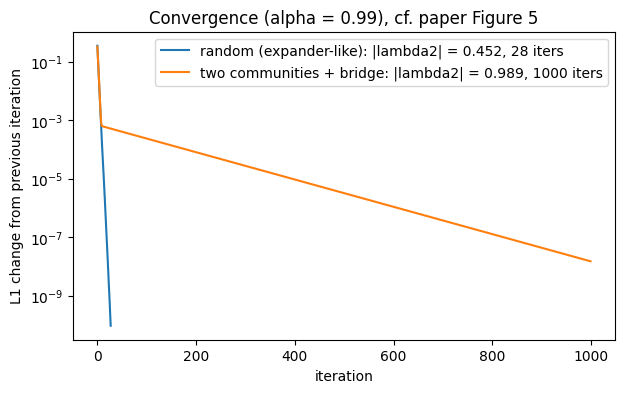

In [15]:
def random_out_graph(n, k, seed):
    # Each node links to k random other nodes: a classic expander-like random digraph.
    r = np.random.default_rng(seed)
    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    for u in range(n):
        targets = r.choice([v for v in range(n) if v != u], size=k, replace=False)
        G.add_edges_from((u, int(v)) for v in targets)
    return G

def two_communities(n_each, k, seed):
    A = random_out_graph(n_each, k, seed)
    B = nx.relabel_nodes(random_out_graph(n_each, k, seed + 1), lambda x: x + n_each)
    G = nx.compose(A, B)
    G.add_edge(0, n_each)          # one thin bridge each way
    G.add_edge(n_each, 0)
    return G

def second_eig(G, alpha):
    M, nodes = transition_matrix(G)
    n = len(nodes)
    Gm = alpha * M + (1 - alpha) / n * np.ones((n, n))     # the full "Google matrix"
    vals = np.sort(np.abs(np.linalg.eigvals(Gm)))[::-1]
    return vals[1]

alpha = 0.99
G_exp = random_out_graph(200, 5, seed=1)
G_bot = two_communities(100, 5, seed=1)

fig, ax = plt.subplots(figsize=(7, 4))
for name, G in [("random (expander-like)", G_exp), ("two communities + bridge", G_bot)]:
    _, hist = pagerank(G, alpha=alpha, tol=1e-10, return_history=True)
    resid = np.abs(np.diff(hist, axis=0)).sum(axis=1)
    lam2 = second_eig(G, alpha)
    ax.semilogy(resid, label=f"{name}: |lambda2| = {lam2:.3f}, {len(resid)} iters")
ax.set_xlabel("iteration"); ax.set_ylabel("L1 change from previous iteration")
ax.set_title(f"Convergence (alpha = {alpha}), cf. paper Figure 5")
ax.legend(); plt.show()

In [16]:
def expansion_ratio(G, S):
    # |out-neighborhood of S outside S| / |S|
    out = set()
    for u in S:
        out.update(G.successors(u))
    return len(out - set(S)) / len(S)

r = np.random.default_rng(0)
random_sets = [expansion_ratio(G_exp, list(r.choice(200, 50, replace=False))) for _ in range(200)]
community = expansion_ratio(G_bot, list(range(100)))   # one whole community
print(f"Random graph: worst expansion over 200 random 50-node sets = {min(random_sets):.2f}")
print(f"Bottleneck graph: expansion of one community (100 nodes)   = {community:.2f}")

Random graph: worst expansion over 200 random 50-node sets = 1.88
Bottleneck graph: expansion of one community (100 nodes)   = 0.01


The bottleneck graph contains a large set whose boundary is a single node (it usually hits the 1,000-iteration cap before reaching tolerance), so its expansion ratio is tiny, $|\lambda_2|$ sits close to 1, and convergence crawls. The random graph has no such bottleneck.

### 8a. How does iteration count scale with graph size?

The paper says the number of iterations scales "roughly linear in log n." One important caveat to keep in mind: with damping, Haveliwala and Kamvar (2003) proved $|\lambda_2| \le \alpha$ for the Google matrix. So with $\alpha = 0.85$, the iteration count stays bounded by about $\log \varepsilon / \log 0.85$ *regardless of graph size*. The damping does a lot of the work the paper credits to the Web's structure. Run the cell and judge for yourself. (I use sparse matrices so this scales to larger graphs.)

In [17]:
def sparse_pagerank_iters(G, alpha, tol=1e-8, max_iter=5000):
    n = G.number_of_nodes()
    outdeg = np.array([G.out_degree(u) for u in range(n)], float)
    src, dst = zip(*G.edges())
    M = sp.csr_matrix((1.0 / outdeg[list(src)], (dst, src)), shape=(n, n))
    R = np.ones(n) / n
    for i in range(1, max_iter + 1):
        R_new = alpha * (M @ R) + (1 - alpha) / n
        R_new /= R_new.sum()
        if np.abs(R_new - R).sum() < tol:
            return i
        R = R_new
    return max_iter

sizes = [1_000, 4_000, 16_000, 64_000]
rows = []
for n in sizes:
    G = nx.DiGraph()
    src = np.repeat(np.arange(n), 5)
    dst = rng.integers(0, n, size=5 * n)
    keep = src != dst
    G.add_nodes_from(range(n))
    G.add_edges_from(zip(src[keep].tolist(), dst[keep].tolist()))
    for u in range(n):                       # guarantee no dangling nodes
        if G.out_degree(u) == 0:
            G.add_edge(u, (u + 1) % n)
    rows.append({"n": n, "iters alpha=0.85": sparse_pagerank_iters(G, 0.85),
                 "iters alpha=0.99": sparse_pagerank_iters(G, 0.99)})
pd.DataFrame(rows)

,n,iters alpha=0.85,iters alpha=0.99
0,1000,19,23
1,4000,19,23
2,16000,19,23
3,64000,19,23


On random graphs, the count stays nearly flat as $n$ grows by 64×. That's consistent with "rapid mixing" (logarithmic or better), and it's the practical reason PageRank scales to the whole Web.

> **Try it:** replace the random graph with `two_communities` at growing sizes and set alpha to 0.999. Watch the iteration count climb.

## 9. Personalized PageRank (Section 6, Table 2)

E doesn't have to be uniform. If the surfer always "teleports" back to one home page, you get rankings *from that page's point of view*. The paper compares $E$ = John McCarthy's home page against $E$ = Netscape's home page (Table 2), and computer science pages rank higher from McCarthy's view.

**Analogy:** uniform E resembles asking "who is famous?" Personalized E resembles asking "who is famous *among people within a few handshakes of me*?" The surfer keeps getting yanked back home, so pages near home get visited more.

**Graph theory name:** a **random walk with restart**. This idea later grew into Topic-Sensitive PageRank (Haveliwala 2002).

We build a toy web with a CS-academic cluster and a commercial cluster, joined by a few cross-links.

In [18]:
Gp = nx.DiGraph([
    # academic CS cluster
    ("McCarthy", "StanfordCS"), ("McCarthy", "Mitchell"), ("McCarthy", "TheoryGroup"),
    ("Mitchell", "TheoryGroup"), ("Mitchell", "StanfordCS"), ("TheoryGroup", "Mitchell"),
    ("TheoryGroup", "StanfordCS"), ("StanfordCS", "McCarthy"), ("StanfordCS", "Toronto"),
    ("Toronto", "StanfordCS"), ("Toronto", "MichiganAI"), ("MichiganAI", "Toronto"),
    # commercial cluster
    ("Netscape", "Download"), ("Netscape", "Yahoo"), ("Download", "Netscape"),
    ("Yahoo", "Netscape"), ("Yahoo", "Shop"), ("Shop", "Yahoo"), ("Shop", "Netscape"),
    ("Yahoo", "VentureLaw"), ("VentureLaw", "Yahoo"),
    # bridges
    ("Yahoo", "StanfordCS"), ("StanfordCS", "Netscape"), ("Mitchell", "VentureLaw"),
])

views = {
    "uniform E": pagerank(Gp),
    "E = McCarthy": pagerank(Gp, e={"McCarthy": 1}),
    "E = Netscape": pagerank(Gp, e={"Netscape": 1}),
}
tbl = pd.DataFrame(views)
pct = tbl.rank(pct=True) * 100      # percentiles, as in the paper's Table 2
print("Raw PageRank:")
display(tbl.round(4).sort_values("E = McCarthy", ascending=False))
print("Percentile (the paper reports these; note how they compress differences at the top):")
display(pct.round(1).sort_values("E = McCarthy", ascending=False))

Raw PageRank:


,uniform E,E = McCarthy,E = Netscape
McCarthy,0.0527,0.1984,0.0205
StanfordCS,0.1380,0.1709,0.0723
Netscape,0.1896,0.1245,0.3709
Yahoo,0.1684,0.1027,0.2193
Mitchell,0.0463,0.0911,0.0094
TheoryGroup,0.0417,0.0820,0.0085
Toronto,0.1007,0.0758,0.0321
Download,0.0942,0.0529,0.1576
VentureLaw,0.0625,0.0476,0.0493
MichiganAI,0.0564,0.0322,0.0136


Percentile (the paper reports these; note how they compress differences at the top):


,uniform E,E = McCarthy,E = Netscape
McCarthy,36.4,100.0,36.4
StanfordCS,81.8,90.9,72.7
Netscape,100.0,81.8,100.0
Yahoo,90.9,72.7,90.9
Mitchell,18.2,63.6,18.2
TheoryGroup,9.1,54.5,9.1
Toronto,72.7,45.5,45.5
Download,63.6,36.4,81.8
VentureLaw,54.5,27.3,63.6
MichiganAI,45.5,18.2,27.3


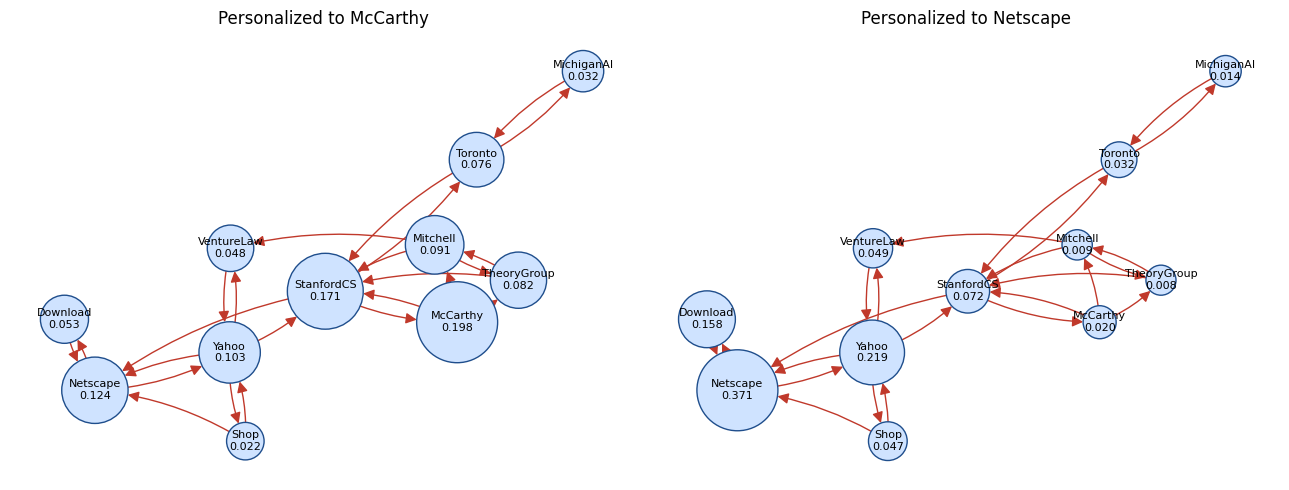

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pos_p = nx.spring_layout(Gp, seed=7)
draw(Gp, views["E = McCarthy"], "Personalized to McCarthy", pos=pos_p, ax=axes[0])
draw(Gp, views["E = Netscape"], "Personalized to Netscape", pos=pos_p, ax=axes[1])
plt.tight_layout(); plt.show()

**What to notice:** the home node ranks highest in its own view, its immediate links come next, and the disparity fades with distance. The paper reports exactly this pattern ("the respective home page got the highest PageRank and was followed by its immediate links"). Also note the paper's caution that percentiles compress large raw differences at the top of the range; compare the two tables above.

## 10. Manipulation and link farms (Section 6.1)

The paper argues personalized PageRank is "virtually immune to manipulation by commercial interests," and that uniform or root-page-based E can be gamed by creating lots of pages.

The graph theory reason is **reachability**. Under personalized E, rank originates only at the restart node. A spam page can only gain rank if some path leads to it *from the restart set*. A **link farm** (many fake pages pointing at a target) creates no such path, because nobody legitimate links into the farm.

**Analogy:** under uniform E, every page gets a free sprinkler. Build 1,000 fake pages and you've installed 1,000 sprinklers that all drain into your target. Under personalized E, only the trusted home page has a sprinkler, and your fake pages sit in a dry field that no pipe from home reaches.

(This reachability argument underlies later anti-spam work such as TrustRank; Gyöngyi, Garcia-Molina, and Pedersen 2004.)

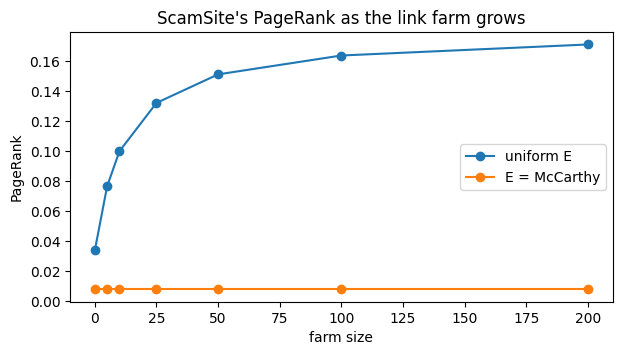

,uniform E,E = McCarthy,uniform E (rank position)
farm size,,,
0,0.03382,0.00783,12
5,0.07659,0.00783,6
10,0.09992,0.00783,4
25,0.13207,0.00783,4
50,0.15109,0.00783,3
100,0.16365,0.00783,2
200,0.17100,0.00783,2


In [20]:
def add_link_farm(G, target, k):
    H = G.copy()
    for i in range(k):
        H.add_edge(f"spam{i}", target)
    return H

H0 = Gp.copy()
H0.add_edge("Shop", "ScamSite"); H0.add_edge("ScamSite", "Shop")   # target with one honest-ish link

ks = [0, 5, 10, 25, 50, 100, 200]
res = []
for k in ks:
    H = add_link_farm(H0, "ScamSite", k)
    res.append({
        "farm size": k,
        "uniform E": pagerank(H)["ScamSite"],
        "E = McCarthy": pagerank(H, e={"McCarthy": 1})["ScamSite"],
        "uniform E (rank position)": sorted(pagerank(H).values(), reverse=True).index(pagerank(H)["ScamSite"]) + 1,
    })
farm = pd.DataFrame(res).set_index("farm size")
farm[["uniform E", "E = McCarthy"]].plot(marker="o", figsize=(7, 3.5),
                                        title="ScamSite's PageRank as the link farm grows")
plt.ylabel("PageRank"); plt.show()
farm.round(5)

Under uniform E, ScamSite climbs toward the top as the farm grows. Under McCarthy-personalized E, the farm has **zero** effect, because no path leads from McCarthy into the spam pages. (Note that total rank gets spread over more pages as the farm grows, so look at the rank position column too, not just the raw score.)

> **Try it:** add a single edge `("Yahoo", "spam0")` (someone buys one link on an important site, which the paper says "costs money"). How much does the personalized ranking now move?

## 11. PageRank vs. Kleinberg's HITS (related work, Section 2.1)

The paper cites Kleinberg's **Hubs and Authorities** model as concurrent work. Both compute eigenvectors of link matrices, but they model importance differently:

* **PageRank:** one score per page. You matter if important pages point to you.
* **HITS:** two scores. A good **authority** gets pointed to by good hubs; a good **hub** points to good authorities. These are the dominant eigenvectors of $A^{\mathsf T}A$ (co-citation) and $AA^{\mathsf T}$ (bibliographic coupling).

**Analogy:** PageRank asks "how prestigious are you?" HITS asks two questions: "do you *write* good bibliographies?" (hub) and "do you *get cited* by good bibliographies?" (authority). A literature review paper makes a great hub; a seminal paper makes a great authority.

Below: a larger scale-free graph (heavy-tailed degrees, like the Web), comparing in-degree, PageRank, and HITS authority.

Spearman rank correlations:


,in-degree,PageRank,HITS authority
in-degree,1.000,0.993,0.896
PageRank,0.993,1.000,0.890
HITS authority,0.896,0.890,1.000


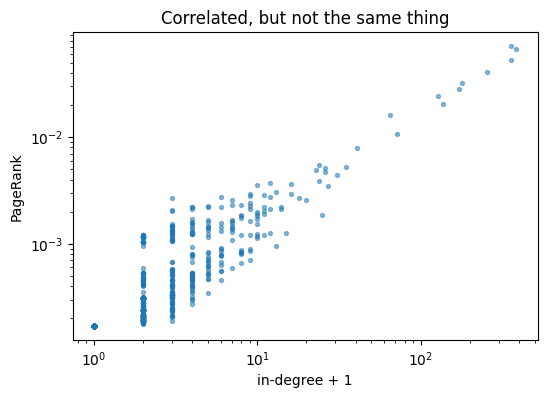

,in-degree,PageRank,HITS authority,rank by in-degree
0,358,0.07132,0.09828,2
2,385,0.06713,0.11302,1
3,357,0.05272,0.09642,3
1,253,0.04077,0.06648,4
9,178,0.03227,0.04213,5
17,171,0.02816,0.04020,6
20,126,0.02420,0.03128,8
13,136,0.02036,0.03296,7
4,64,0.01617,0.01517,10
8,71,0.01079,0.01934,9


In [21]:
from scipy.stats import spearmanr
Gsf = nx.DiGraph(nx.scale_free_graph(2000, seed=4))
Gsf.remove_edges_from(nx.selfloop_edges(Gsf))

prs = nx.pagerank(Gsf)
hubs, auths = nx.hits(Gsf, max_iter=1000)
indeg = dict(Gsf.in_degree())
nodes_sf = list(Gsf)
X = pd.DataFrame({"in-degree": [indeg[u] for u in nodes_sf],
                  "PageRank": [prs[u] for u in nodes_sf],
                  "HITS authority": [auths[u] for u in nodes_sf]}, index=nodes_sf)

print("Spearman rank correlations:")
display(X.corr(method="spearman").round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X["in-degree"] + 1, X["PageRank"], s=8, alpha=0.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("in-degree + 1"); ax.set_ylabel("PageRank")
ax.set_title("Correlated, but not the same thing")
plt.show()

top = X.sort_values("PageRank", ascending=False).head(10)
top["rank by in-degree"] = X["in-degree"].rank(ascending=False, method="min")[top.index].astype(int)
top.round(5)

PageRank and in-degree correlate strongly on average, yet the ordering at the top differs, which is exactly where search results live. The paper's Section 7.2 makes a related, stronger claim from a follow-up study (Cho, Garcia-Molina, and Page 1998): on the Stanford web, PageRank computed on a *partial* crawl predicted future citation counts better than the citation counts observed so far.

---
## Exercises

1. **Damping sweep.** Plot each node's PageRank in `Gsink` as alpha goes from 0.5 to 0.999. Which nodes gain as alpha approaches 1, and why does that connect to Section 5?
2. **Rebuild Figure 2.** Construct a graph where one page holds 100 with two out-links and another holds 9 with three out-links, and label edges with the flow. (Hint: you need to choose the rest of the graph so those values form a steady state.)
3. **Crawl ordering (Section 7.2).** Starting from one seed node in `Gsf`, simulate a crawler that picks the next frontier page by (a) known backlink count, or (b) PageRank on the discovered subgraph. Plot the fraction of the true top-5% in-degree pages found vs. pages crawled. Does PageRank win on synthetic graphs, as the paper reports for real ones? (I don't know the answer for this generator; it depends on graph structure.)
4. **Root-page E (Section 6.1).** Mark some nodes as "root pages," set E uniform over them, then let the attacker add new root pages pointing at a target. Show the paper's claim that this compromise "will allow some manipulation."
5. **Bipartite trap.** Build a graph where every cycle has even length and run the simplified ranking without damping. What happens, and which Markov-chain property fails?

---
## References (Chicago 18th ed., bibliography style)

Confidence ratings note how sure I am of the bibliographic details, not of the ideas. Please verify page ranges before citing in a submission.

Bonacich, Phillip. "Power and Centrality: A Family of Measures." *American Journal of Sociology* 92, no. 5 (1987): 1170–82. *(Confidence: high.)*

Brin, Sergey, and Lawrence Page. "The Anatomy of a Large-Scale Hypertextual Web Search Engine." *Computer Networks and ISDN Systems* 30, nos. 1–7 (1998): 107–17. *(Confidence: high. Source of the standard damping-factor formulation.)*

Cho, Junghoo, Hector Garcia-Molina, and Lawrence Page. "Efficient Crawling Through URL Ordering." *Computer Networks and ISDN Systems* 30, nos. 1–7 (1998): 161–72. *(Confidence: medium-high on page range.)*

Frobenius, Georg. "Über Matrizen aus nicht negativen Elementen." *Sitzungsberichte der Königlich Preussischen Akademie der Wissenschaften* (1912): 456–77. *(Confidence: medium-high.)*

Gyöngyi, Zoltán, Hector Garcia-Molina, and Jan Pedersen. "Combating Web Spam with TrustRank." In *Proceedings of the 30th International Conference on Very Large Data Bases*, 576–87. 2004. *(Confidence: medium-high.)*

Haveliwala, Taher H. "Topic-Sensitive PageRank." In *Proceedings of the 11th International Conference on World Wide Web*, 517–26. ACM, 2002. *(Confidence: high.)*

Haveliwala, Taher H., and Sepandar D. Kamvar. "The Second Eigenvalue of the Google Matrix." Technical Report 2003-20. Stanford InfoLab, 2003. *(Confidence: high on the result; medium on the report number.)*

Hoory, Shlomo, Nathan Linial, and Avi Wigderson. "Expander Graphs and Their Applications." *Bulletin of the American Mathematical Society* 43, no. 4 (2006): 439–561. *(Confidence: high.)*

Katz, Leo. "A New Status Index Derived from Sociometric Analysis." *Psychometrika* 18, no. 1 (1953): 39–43. *(Confidence: high.)*

Kleinberg, Jon M. "Authoritative Sources in a Hyperlinked Environment." *Journal of the ACM* 46, no. 5 (1999): 604–32. *(Confidence: high. The paper cites the 1998 SODA version.)*

Langville, Amy N., and Carl D. Meyer. *Google's PageRank and Beyond: The Science of Search Engine Rankings*. Princeton University Press, 2006. *(Confidence: high. Best single textbook on everything in this notebook.)*

Motwani, Rajeev, and Prabhakar Raghavan. *Randomized Algorithms*. Cambridge University Press, 1995. *(Confidence: high.)*

Norris, J. R. *Markov Chains*. Cambridge University Press, 1997. *(Confidence: high.)*

Page, Lawrence, Sergey Brin, Rajeev Motwani, and Terry Winograd. "The PageRank Citation Ranking: Bringing Order to the Web." Technical Report 1999-66. Stanford InfoLab, 1999. *(Confidence: high.)*

Perron, Oskar. "Zur Theorie der Matrices." *Mathematische Annalen* 64 (1907): 248–63. *(Confidence: medium-high.)*

Pinski, Gabriel, and Francis Narin. "Citation Influence for Journal Aggregates of Scientific Publications: Theory, with Application to the Literature of Physics." *Information Processing & Management* 12, no. 5 (1976): 297–312. *(Confidence: high. An eigenvector citation-ranking method that predates PageRank by two decades.)*

Vigna, Sebastiano. "Spectral Ranking." *Network Science* 4, no. 4 (2016): 433–45. *(Confidence: medium-high. A history of eigenvector ranking ideas going back to the 1940s.)*